# Exploración y limpieza con todos los préstamos

Este notebook carga las 97 columnas seleccionadas con tipos compactos, revisa los faltantes en la primera ventana de entrenamiento (préstamos elegibles hasta 2012) y conserva las 26 predictoras con menos del 10% de faltantes en esa ventana. Compara las distribuciones antes y después de una imputación **solo descriptiva**. No entrena modelos ni usa el periodo de prueba para esta comparación.

## 1. Preparar la lectura y los nombres para presentar

In [3]:
from pathlib import Path
import sys
import time
import gc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

carpeta = Path.cwd()
if carpeta.name == "notebooks":
    carpeta = carpeta.parent
if str(carpeta) not in sys.path:
    sys.path.insert(0, str(carpeta))

from src.config import localizar_datos, ANIO_CORTE_VALIDACION, ANIO_CORTE_PRUEBA, UMBRAL_FALTANTES_FINAL as UMBRAL_FALTANTES
from src.features import seleccionar_predictoras, preparar_matriz

archivo = localizar_datos()
print("Archivo:", archivo)
print(f"Tamaño en disco: {archivo.stat().st_size / 1024**3:.2f} GiB")

tipos_auditados = {'acc_now_delinq': 'Int8', 'acc_open_past_24mths': 'Int8', 'addr_state': 'category', 'all_util': 'Int16', 'annual_inc': 'float64', 'annual_inc_joint': 'float64', 'application_type': 'category', 'avg_cur_bal': 'Int32', 'bc_open_to_buy': 'Int32', 'bc_util': 'float64', 'chargeoff_within_12_mths': 'Int8', 'collection_recovery_fee': 'float64', 'collections_12_mths_ex_med': 'Int8', 'debt_settlement_flag': 'category', 'debt_settlement_flag_date': 'category', 'deferral_term': 'Int8', 'delinq_2yrs': 'Int8', 'delinq_amnt': 'Int32', 'desc': 'string', 'disbursement_method': 'category', 'dti': 'float64', 'dti_joint': 'float64', 'earliest_cr_line': 'string', 'emp_length': 'category', 'emp_title': 'string', 'fico_range_high': 'Int16', 'fico_range_low': 'Int16', 'funded_amnt': 'Int32', 'funded_amnt_inv': 'float64', 'grade': 'category', 'hardship_amount': 'float64', 'hardship_dpd': 'Int8', 'hardship_end_date': 'category', 'hardship_flag': 'category', 'hardship_last_payment_amount': 'float64', 'hardship_length': 'Int8', 'hardship_loan_status': 'category', 'hardship_payoff_balance_amount': 'float64', 'hardship_reason': 'category', 'hardship_start_date': 'category', 'hardship_status': 'category', 'hardship_type': 'category', 'home_ownership': 'category', 'id': 'string', 'il_util': 'Int16', 'initial_list_status': 'category', 'inq_fi': 'Int8', 'inq_last_12m': 'Int8', 'inq_last_6mths': 'Int8', 'installment': 'float64', 'int_rate': 'float64', 'issue_d': 'string', 'last_credit_pull_d': 'category', 'last_fico_range_high': 'Int16', 'last_fico_range_low': 'Int16', 'last_pymnt_amnt': 'float64', 'last_pymnt_d': 'category', 'loan_amnt': 'Int32', 'loan_status': 'category', 'max_bal_bc': 'Int32', 'member_id': 'string', 'mo_sin_old_il_acct': 'Int16', 'mo_sin_old_rev_tl_op': 'Int16', 'mo_sin_rcnt_rev_tl_op': 'Int16', 'mo_sin_rcnt_tl': 'Int16', 'mort_acc': 'Int8', 'mths_since_last_delinq': 'Int16', 'mths_since_last_major_derog': 'Int16', 'mths_since_last_record': 'Int16', 'mths_since_rcnt_il': 'Int16', 'mths_since_recent_bc': 'Int16', 'mths_since_recent_bc_dlq': 'Int16', 'mths_since_recent_inq': 'Int8', 'mths_since_recent_revol_delinq': 'Int16', 'next_pymnt_d': 'category', 'num_accts_ever_120_pd': 'Int8', 'num_actv_bc_tl': 'Int8', 'num_actv_rev_tl': 'Int8', 'num_bc_sats': 'Int8', 'num_bc_tl': 'Int8', 'num_il_tl': 'Int16', 'num_op_rev_tl': 'Int8', 'num_rev_accts': 'Int16', 'num_rev_tl_bal_gt_0': 'Int8', 'num_sats': 'Int8', 'num_tl_120dpd_2m': 'Int8', 'num_tl_30dpd': 'Int8', 'num_tl_90g_dpd_24m': 'Int8', 'num_tl_op_past_12m': 'Int8', 'open_acc': 'Int8', 'open_acc_6m': 'Int8', 'open_act_il': 'Int8', 'open_il_12m': 'Int8', 'open_il_24m': 'Int8', 'open_rv_12m': 'Int8', 'open_rv_24m': 'Int8', 'orig_projected_additional_accrued_interest': 'float64', 'out_prncp': 'float64', 'out_prncp_inv': 'float64', 'payment_plan_start_date': 'category', 'pct_tl_nvr_dlq': 'float64', 'percent_bc_gt_75': 'float64', 'policy_code': 'category', 'pub_rec': 'Int8', 'pub_rec_bankruptcies': 'Int8', 'purpose': 'category', 'pymnt_plan': 'category', 'recoveries': 'float64', 'revol_bal': 'Int32', 'revol_bal_joint': 'Int32', 'revol_util': 'float64', 'sec_app_chargeoff_within_12_mths': 'Int8', 'sec_app_collections_12_mths_ex_med': 'Int8', 'sec_app_earliest_cr_line': 'string', 'sec_app_fico_range_high': 'Int16', 'sec_app_fico_range_low': 'Int16', 'sec_app_inq_last_6mths': 'Int8', 'sec_app_mort_acc': 'Int8', 'sec_app_mths_since_last_major_derog': 'Int16', 'sec_app_num_rev_accts': 'Int8', 'sec_app_open_acc': 'Int8', 'sec_app_open_act_il': 'Int8', 'sec_app_revol_util': 'float64', 'settlement_amount': 'float64', 'settlement_date': 'category', 'settlement_percentage': 'float64', 'settlement_status': 'category', 'settlement_term': 'Int16', 'sub_grade': 'category', 'tax_liens': 'Int8', 'term': 'category', 'title': 'string', 'tot_coll_amt': 'Int32', 'tot_cur_bal': 'Int32', 'tot_hi_cred_lim': 'Int32', 'total_acc': 'Int16', 'total_bal_ex_mort': 'Int32', 'total_bal_il': 'Int32', 'total_bc_limit': 'Int32', 'total_cu_tl': 'Int8', 'total_il_high_credit_limit': 'Int32', 'total_pymnt': 'float64', 'total_pymnt_inv': 'float64', 'total_rec_int': 'float64', 'total_rec_late_fee': 'float64', 'total_rec_prncp': 'float64', 'total_rev_hi_lim': 'Int32', 'url': 'string', 'verification_status': 'category', 'verification_status_joint': 'category', 'zip_code': 'category'}

nombres_variables = {'acc_now_delinq': 'cuentas_en_mora_actual', 'acc_open_past_24mths': 'cuentas_abiertas_ultimos_24m', 'annual_inc': 'ingreso_anual', 'avg_cur_bal': 'saldo_promedio_cuentas', 'bc_open_to_buy': 'credito_disponible_tarjetas', 'bc_util': 'utilizacion_tarjetas_pct', 'chargeoff_within_12_mths': 'cuentas_castigadas_12m', 'collections_12_mths_ex_med': 'cobranzas_no_medicas_12m', 'delinq_2yrs': 'moras_ultimos_2_anios', 'delinq_amnt': 'monto_en_mora_actual', 'dti': 'ratio_deuda_ingreso', 'fico_range_high': 'fico_limite_superior', 'fico_range_low': 'fico_limite_inferior', 'inq_last_6mths': 'consultas_credito_6m', 'loan_amnt': 'monto_prestamo', 'mo_sin_old_il_acct': 'meses_desde_cuenta_plazos_mas_antigua', 'mo_sin_old_rev_tl_op': 'meses_desde_revolvente_mas_antigua', 'mo_sin_rcnt_rev_tl_op': 'meses_desde_revolvente_mas_reciente', 'mo_sin_rcnt_tl': 'meses_desde_cuenta_mas_reciente', 'mort_acc': 'cuentas_hipotecarias', 'mths_since_last_delinq': 'meses_desde_ultima_mora', 'mths_since_last_major_derog': 'meses_desde_ultima_mora_grave', 'mths_since_last_record': 'meses_desde_ultimo_registro_publico', 'mths_since_recent_bc': 'meses_desde_tarjeta_mas_reciente', 'mths_since_recent_bc_dlq': 'meses_desde_ultima_mora_tarjeta', 'mths_since_recent_inq': 'meses_desde_ultima_consulta_credito', 'mths_since_recent_revol_delinq': 'meses_desde_ultima_mora_revolvente', 'num_accts_ever_120_pd': 'cuentas_con_mora_120_dias', 'num_actv_bc_tl': 'tarjetas_bancarias_activas', 'num_actv_rev_tl': 'cuentas_revolventes_activas', 'num_bc_sats': 'tarjetas_bancarias_al_dia', 'num_bc_tl': 'total_cuentas_tarjeta', 'num_il_tl': 'total_cuentas_plazos', 'num_op_rev_tl': 'cuentas_revolventes_abiertas', 'num_rev_accts': 'total_cuentas_revolventes', 'num_rev_tl_bal_gt_0': 'revolventes_con_saldo', 'num_sats': 'cuentas_satisfactorias', 'num_tl_120dpd_2m': 'cuentas_mora_120_dias_ultimos_2m', 'num_tl_30dpd': 'cuentas_mora_30_dias_actual', 'num_tl_90g_dpd_24m': 'cuentas_mora_90_mas_dias_24m', 'num_tl_op_past_12m': 'cuentas_abiertas_12m', 'open_acc': 'lineas_credito_abiertas', 'pct_tl_nvr_dlq': 'pct_cuentas_sin_mora', 'percent_bc_gt_75': 'pct_tarjetas_utilizacion_mayor_75', 'pub_rec': 'registros_publicos_adversos', 'pub_rec_bankruptcies': 'quiebras_registradas', 'revol_bal': 'saldo_credito_revolvente', 'revol_util': 'utilizacion_credito_revolvente_pct', 'tax_liens': 'gravamenes_fiscales', 'term': 'plazo_meses', 'tot_coll_amt': 'monto_total_cobranzas', 'tot_cur_bal': 'saldo_total_actual', 'tot_hi_cred_lim': 'limite_credito_total', 'total_acc': 'total_lineas_credito', 'total_bal_ex_mort': 'saldo_total_sin_hipoteca', 'total_bc_limit': 'limite_total_tarjetas', 'total_il_high_credit_limit': 'limite_total_creditos_plazos', 'total_rev_hi_lim': 'limite_total_credito_revolvente', 'emp_length': 'antiguedad_laboral', 'home_ownership': 'tenencia_vivienda', 'verification_status': 'verificacion_ingresos', 'purpose': 'proposito_prestamo', 'addr_state': 'estado_residencia', 'application_type': 'tipo_solicitud', 'earliest_cr_line': 'fecha_primera_linea_credito', 'issue_d': 'fecha_otorgamiento', 'loan_status': 'estado_prestamo', 'verification_status_joint': 'verificacion_ingresos_conjunta', 'all_util': 'utilizacion_global_pct', 'annual_inc_joint': 'ingreso_anual_conjunto', 'dti_joint': 'ratio_deuda_ingreso_conjunto', 'open_acc_6m': 'creditos_abiertos_6m', 'open_act_il': 'creditos_plazo_activos', 'open_il_12m': 'creditos_plazo_abiertos_12m', 'open_il_24m': 'creditos_plazo_abiertos_24m', 'mths_since_rcnt_il': 'meses_desde_credito_plazo_reciente', 'total_bal_il': 'saldo_total_creditos_plazo', 'il_util': 'utilizacion_creditos_plazo_pct', 'open_rv_12m': 'creditos_revolventes_abiertos_12m', 'open_rv_24m': 'creditos_revolventes_abiertos_24m', 'max_bal_bc': 'saldo_maximo_tarjetas', 'inq_fi': 'consultas_financieras', 'total_cu_tl': 'cuentas_credito_uniones', 'inq_last_12m': 'consultas_credito_12m', 'revol_bal_joint': 'saldo_revolvente_conjunto', 'sec_app_fico_range_low': 'fico_inferior_solicitante_secundario', 'sec_app_fico_range_high': 'fico_superior_solicitante_secundario', 'sec_app_earliest_cr_line': 'fecha_credito_mas_antiguo_secundario', 'sec_app_inq_last_6mths': 'consultas_credito_6m_secundario', 'sec_app_mort_acc': 'cuentas_hipotecarias_secundario', 'sec_app_open_acc': 'lineas_credito_abiertas_secundario', 'sec_app_revol_util': 'utilizacion_revolvente_secundario_pct', 'sec_app_open_act_il': 'creditos_plazo_activos_secundario', 'sec_app_num_rev_accts': 'cuentas_revolventes_secundario', 'sec_app_chargeoff_within_12_mths': 'castigos_12m_secundario', 'sec_app_collections_12_mths_ex_med': 'cobranzas_12m_secundario', 'sec_app_mths_since_last_major_derog': 'meses_desde_mora_grave_secundario', 'meses_desde_earliest_cr_line': 'antiguedad_historial_crediticio_meses', 'meses_desde_sec_app_earliest_cr_line': 'antiguedad_historial_secundario_meses', 'default': 'incumplimiento'}

def mostrar_nombres_espanol(tabla):
    vista = tabla.copy()
    vista.index = [nombres_variables.get(str(nombre), str(nombre)) for nombre in vista.index]
    vista.columns = [nombres_variables.get(str(nombre), str(nombre)) for nombre in vista.columns]
    return vista




Archivo: C:\Users\josue\Downloads\accepted_2007_to_2018Q4.csv.gz
Tamaño en disco: 0.37 GiB


## 2. Cargar de golpe las 97 columnas con tipos compactos

Se cargan 95 predictoras candidatas, `loan_status` para definir el resultado y `issue_d` para identificar el año del préstamo. Los tipos compactos provienen de la auditoría de rangos y conservan los valores y faltantes. Después de cargar, presentamos el tamaño del DataFrame y distinguimos variables numéricas, categóricas y fechas auxiliares.

In [5]:
columnas_fuente = pd.read_csv(archivo, nrows=0).columns.tolist()
tabla_vacia = pd.DataFrame(columns=columnas_fuente)
candidatas = seleccionar_predictoras(tabla_vacia, [], incluir_precio_lc=False)
columnas_revision = [c for c in columnas_fuente if c in set(candidatas + ["loan_status", "issue_d"])]
assert len(candidatas) == 95 and len(columnas_revision) == 97

# Las categorías y fechas se leen primero como texto; luego se convierten.
dtype_lectura = {}
for columna in columnas_revision:
    sugerido = tipos_auditados[columna]
    dtype_lectura[columna] = sugerido if sugerido not in ["category", "string"] else "string"

inicio = time.perf_counter()
df = pd.read_csv(
    archivo,
    usecols=columnas_revision,
    dtype=dtype_lectura,
    skipinitialspace=True,
    low_memory=False,
)
for columna in df.select_dtypes(include="string").columns:
    df[columna] = df[columna].astype("category")
for columna in ["issue_d", "earliest_cr_line", "sec_app_earliest_cr_line"]:
    if columna in df.columns:
        df[columna] = pd.to_datetime(df[columna], format="%b-%Y", errors="coerce")
if "term" in df.columns:
    df["term"] = pd.to_numeric(
        df["term"].astype("string").str.strip().str.replace(" months", "", regex=False),
        errors="coerce",
    ).astype("Int8")

memoria_df = df.memory_usage(index=True, deep=True).sum()
print(f"Filas y columnas: {df.shape[0]:,} × {df.shape[1]}")
print(f"Carga y conversión: {time.perf_counter() - inicio:.1f} segundos")
print(f"Memoria profunda del DataFrame: {memoria_df / 1024**3:.2f} GiB")

def clasificar_tipo(columna):
    serie = df[columna]
    if pd.api.types.is_datetime64_any_dtype(serie):
        return "fecha auxiliar"
    if pd.api.types.is_numeric_dtype(serie):
        return "numérica"
    return "categórica"

tabla_tipos = pd.DataFrame({
    "tipo_pandas": df.dtypes.astype(str),
    "tipo_de_variable": [clasificar_tipo(c) for c in df.columns],
})
print("Cantidad por tipo:", tabla_tipos["tipo_de_variable"].value_counts().to_dict())
display(mostrar_nombres_espanol(tabla_tipos))
print("Vista de las primeras filas:")
display(df.head().rename(columns=nombres_variables))


Filas y columnas: 2,260,701 × 97
Carga y conversión: 86.9 segundos
Memoria profunda del DataFrame: 0.68 GiB
Cantidad por tipo: {'numérica': 86, 'categórica': 8, 'fecha auxiliar': 3}
Vista de las primeras filas:


,tipo_pandas,tipo_de_variable
monto_prestamo,Int32,numérica
plazo_meses,Int8,numérica
antiguedad_laboral,category,categórica
tenencia_vivienda,category,categórica
ingreso_anual,float64,numérica
verificacion_ingresos,category,categórica
fecha_otorgamiento,timestamp[us][pyarrow],fecha auxiliar
estado_prestamo,category,categórica
proposito_prestamo,category,categórica
estado_residencia,category,categórica


,monto_prestamo,plazo_meses,antiguedad_laboral,tenencia_vivienda,ingreso_anual,verificacion_ingresos,fecha_otorgamiento,estado_prestamo,proposito_prestamo,estado_residencia,ratio_deuda_ingreso,moras_ultimos_2_anios,fecha_primera_linea_credito,fico_limite_inferior,fico_limite_superior,...,limite_total_tarjetas,limite_total_creditos_plazos,saldo_revolvente_conjunto,fico_inferior_solicitante_secundario,fico_superior_solicitante_secundario,fecha_credito_mas_antiguo_secundario,consultas_credito_6m_secundario,cuentas_hipotecarias_secundario,lineas_credito_abiertas_secundario,utilizacion_revolvente_secundario_pct,creditos_plazo_activos_secundario,cuentas_revolventes_secundario,castigos_12m_secundario,cobranzas_12m_secundario,meses_desde_mora_grave_secundario
0,3600,36,10+ years,MORTGAGE,55000.0,Not Verified,2015-12-01 00:00:00,Fully Paid,debt_consolidation,PA,5.91,0,2003-08-01 00:00:00,675,679,...,2400,13734,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,<NA>
1,24700,36,10+ years,MORTGAGE,65000.0,Not Verified,2015-12-01 00:00:00,Fully Paid,small_business,SD,16.06,1,1999-12-01 00:00:00,715,719,...,79300,24667,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,<NA>
2,20000,60,10+ years,MORTGAGE,63000.0,Not Verified,2015-12-01 00:00:00,Fully Paid,home_improvement,IL,10.78,0,2000-08-01 00:00:00,695,699,...,6200,14877,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,<NA>
3,35000,60,10+ years,MORTGAGE,110000.0,Source Verified,2015-12-01 00:00:00,Current,debt_consolidation,NJ,17.06,0,2008-09-01 00:00:00,785,789,...,62500,18000,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,<NA>
4,10400,60,3 years,MORTGAGE,104433.0,Source Verified,2015-12-01 00:00:00,Fully Paid,major_purchase,PA,25.37,1,1998-06-01 00:00:00,695,699,...,20300,88097,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,<NA>


## 3. Definir la población y los periodos de análisis

### 3.1. Seleccionar los préstamos y establecer los cortes

Conservamos préstamos con resultado final `Fully Paid` o `Charged Off`. En esta sección definimos los grupos de entrenamiento, validación y prueba, y la primera ventana hasta 2012 para revisar faltantes. La distribución del objetivo se presenta por separado en la sección 3.2. Aquí no se detalla el procedimiento de validación cruzada.

In [7]:
estados_conservados = ["Fully Paid", "Charged Off"]
anios = df["issue_d"].dt.year
mascara_elegible = df["loan_status"].isin(estados_conservados) & anios.notna()
mascara_hasta_2012 = mascara_elegible & (anios <= 2012)

estados = df["loan_status"].value_counts(dropna=False).to_frame("cantidad")
estados["porcentaje_archivo"] = estados["cantidad"] / len(df) * 100
print("Estados observados en el archivo de origen:")
display(estados)
print("Estados con resultado final que se conservan:", estados_conservados)
print(f"Préstamos elegibles hasta 2012: {int(mascara_hasta_2012.sum()):,}")

mascara_desarrollo = mascara_elegible & (anios < ANIO_CORTE_PRUEBA)
mascara_prueba = mascara_elegible & (anios >= ANIO_CORTE_PRUEBA)
resumen_periodos = pd.DataFrame([
    {"conjunto": "entrenamiento", "periodo": f"antes de {ANIO_CORTE_VALIDACION}", "filas": int((mascara_elegible & (anios < ANIO_CORTE_VALIDACION)).sum())},
    {"conjunto": "validación", "periodo": f"{ANIO_CORTE_VALIDACION}–{ANIO_CORTE_PRUEBA-1}", "filas": int((mascara_elegible & anios.between(ANIO_CORTE_VALIDACION, ANIO_CORTE_PRUEBA-1)).sum())},
    {"conjunto": "prueba reservada", "periodo": f"desde {ANIO_CORTE_PRUEBA}", "filas": int(mascara_prueba.sum())},
])
print("Cortes temporales aplicados:")
display(resumen_periodos)


Estados observados en el archivo de origen:
Estados con resultado final que se conservan: ['Fully Paid', 'Charged Off']
Préstamos elegibles hasta 2012: 93,153
Cortes temporales aplicados:


,cantidad,porcentaje_archivo
loan_status,,
Fully Paid,1076751,47.629076
Current,878317,38.851533
Charged Off,268559,11.879457
Late (31-120 days),21467,0.949573
In Grace Period,8436,0.373159
Late (16-30 days),4349,0.192374
Does not meet the credit policy. Status:Fully Paid,1988,0.087937
Does not meet the credit policy. Status:Charged Off,761,0.033662
Default,40,0.001769


,conjunto,periodo,filas
0,entrenamiento,antes de 2015,451059
1,validación,2015–2016,668640
2,prueba reservada,desde 2017,225611


### 3.2. Distribución de la variable objetivo

La gráfica muestra únicamente los préstamos elegibles con resultado final. Las etiquetas indican la cantidad y el porcentaje de cada clase. El eje vertical muestra cantidades completas y se reserva espacio sobre las barras para que las etiquetas no se corten ni se monten con la escala.


,cantidad,porcentaje
loan_status,,
Fully Paid,1076751,80.037389
Charged Off,268559,19.962611


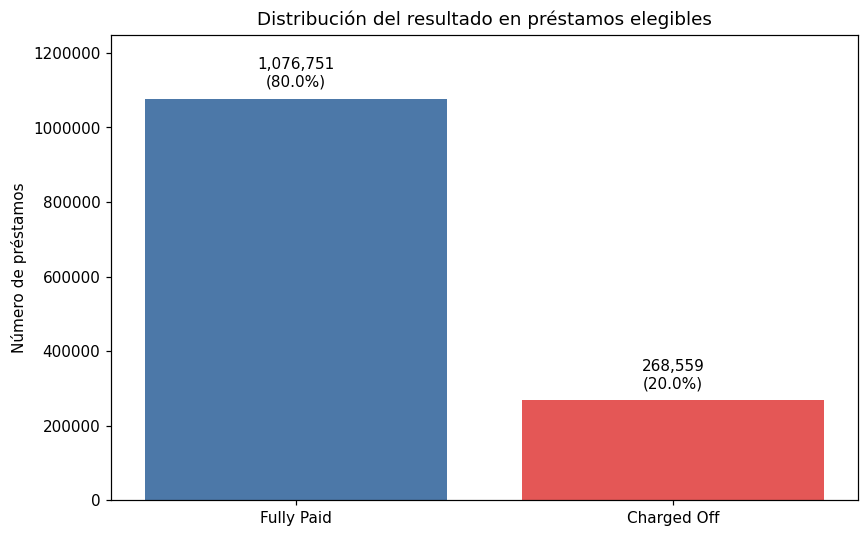

In [9]:
y_total = df.loc[mascara_elegible, "loan_status"].map({"Fully Paid": 0, "Charged Off": 1})
tabla_objetivo = y_total.value_counts().sort_index().rename(
    index={0: "Fully Paid", 1: "Charged Off"}
).to_frame("cantidad")
tabla_objetivo["porcentaje"] = tabla_objetivo["cantidad"] / tabla_objetivo["cantidad"].sum() * 100
display(tabla_objetivo)

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(
    tabla_objetivo.index.astype(str),
    tabla_objetivo["cantidad"],
    color=["#4C78A8", "#E45756"],
)
ax.set_title("Distribución del resultado en préstamos elegibles")
ax.set_ylabel("Número de préstamos")
ax.ticklabel_format(axis="y", style="plain", useOffset=False)
ax.set_ylim(0, tabla_objetivo["cantidad"].max() * 1.16)

for i, barra in enumerate(barras):
    cantidad = int(tabla_objetivo["cantidad"].iloc[i])
    porcentaje = tabla_objetivo["porcentaje"].iloc[i]
    ax.annotate(
        f"{cantidad:,}\n({porcentaje:.1f}%)",
        xy=(barra.get_x() + barra.get_width() / 2, barra.get_height()),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
    )

fig.tight_layout()
plt.show()


### 3.3. Auditoría de faltantes en la primera ventana de entrenamiento

Revisamos los faltantes de las 97 columnas en los préstamos elegibles otorgados hasta 2012, que forman la primera ventana de entrenamiento antes de la validación de 2013. Esta tabla sirve para documentar qué información estaría disponible al iniciar la validación temporal. La selección de predictoras se explica en la sección 4; `loan_status` e `issue_d` se muestran como columnas auxiliares y no cuentan como predictoras.

In [ ]:
# La auditoría de cobertura se limita a la primera ventana de entrenamiento: préstamos hasta 2012.
filas_referencia = int(mascara_hasta_2012.sum())
faltantes_hasta_2012 = df.loc[mascara_hasta_2012, columnas_revision].isna().sum()
observados_hasta_2012 = filas_referencia - faltantes_hasta_2012
porcentaje_hasta_2012 = faltantes_hasta_2012 / filas_referencia * 100

tabla_faltantes_hasta_2012 = pd.DataFrame({
    "registros_con_dato": observados_hasta_2012,
    "registros_faltantes": faltantes_hasta_2012,
    "porcentaje_faltante": porcentaje_hasta_2012,
    "al_menos_10_pct": np.where(porcentaje_hasta_2012 >= 10, "Sí", "No"),
})
tabla_faltantes_hasta_2012 = tabla_faltantes_hasta_2012.loc[
    tabla_faltantes_hasta_2012["registros_faltantes"] > 0
].sort_values("porcentaje_faltante", ascending=False)
tabla_faltantes_hasta_2012.index.name = "variable"

print(f"Préstamos elegibles hasta 2012 revisados: {filas_referencia:,}")
print(f"Variables con al menos un faltante: {len(tabla_faltantes_hasta_2012)} de {len(columnas_revision)}")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(mostrar_nombres_espanol(tabla_faltantes_hasta_2012.round(4)))

# Guardamos la auditoría completa de la primera ventana, incluidas las columnas auxiliares.
ruta_auditoria_faltantes = carpeta / "outputs" / "avance" / "completo"
ruta_auditoria_faltantes.mkdir(parents=True, exist_ok=True)
mostrar_nombres_espanol(tabla_faltantes_hasta_2012.round(4)).to_csv(
    ruta_auditoria_faltantes / "faltantes_97_hasta_2012.csv",
    index_label="variable",
    encoding="utf-8-sig",
)

## 4. Criterio para conservar predictoras

De las **95 predictoras candidatas**, conservamos las que tienen **menos del 10% de faltantes** entre los préstamos elegibles otorgados hasta 2012. Así, la lista fija de variables está disponible desde el primer corte (entrenamiento hasta 2012 y validación en 2013) y puede usarse al comparar todos los modelos. En este análisis quedan **26 predictoras**; `loan_status` e `issue_d` son auxiliares y no forman parte de esa cuenta.

El 10% es un criterio práctico elegido para este proyecto, no un límite universal ni una prueba de que estas sean las variables más predictivas. Las variables descartadas podrían contener información útil, pero su cobertura en la primera ventana es menor. La limitación se documenta para interpretar los resultados.

In [ ]:
# Seleccionamos una lista fija usando solo la primera ventana de entrenamiento (hasta 2012).
# La regla no consulta los años de validación ni el periodo de prueba.
porcentaje_predictoras_hasta_2012 = porcentaje_hasta_2012.reindex(candidatas)
columnas_excluidas_10 = porcentaje_predictoras_hasta_2012[
    porcentaje_predictoras_hasta_2012 >= UMBRAL_FALTANTES
].index.tolist()
predictoras_conservadas = [
    c for c in candidatas if c not in columnas_excluidas_10
]

# Tabla de cobertura para las predictoras; las auxiliares no intervienen en la decisión.
tipos_predictoras = pd.Series(
    {c: clasificar_tipo(c) for c in candidatas}, name="tipo"
)
tabla_cobertura_predictoras = pd.DataFrame({
    "observados_hasta_2012": observados_hasta_2012.reindex(candidatas),
    "faltantes_hasta_2012": faltantes_hasta_2012.reindex(candidatas).fillna(
        filas_referencia - observados_hasta_2012.reindex(candidatas)
    ),
    "porcentaje_faltante_hasta_2012": porcentaje_predictoras_hasta_2012,
    "tipo": tipos_predictoras,
    "decision": np.where(
        porcentaje_predictoras_hasta_2012 < UMBRAL_FALTANTES,
        "conservar", "excluir"
    ),
}).sort_values("porcentaje_faltante_hasta_2012", ascending=False)

print(f"Préstamos elegibles usados para el criterio: {filas_referencia:,} (hasta 2012)")
print(f"Predictoras candidatas iniciales: {len(candidatas)}")
print(f"Excluidas por tener {UMBRAL_FALTANTES}% o más de faltantes: {len(columnas_excluidas_10)}")
print(f"Conservadas con menos del {UMBRAL_FALTANTES}%: {len(predictoras_conservadas)}")
print("Predictoras excluidas:")
display(mostrar_nombres_espanol(tabla_cobertura_predictoras.loc[columnas_excluidas_10].round(3)))
print("Predictoras conservadas:")
tabla_predictoras_conservadas = tabla_cobertura_predictoras.loc[predictoras_conservadas].sort_values(
    "porcentaje_faltante_hasta_2012", ascending=False
)
display(mostrar_nombres_espanol(tabla_predictoras_conservadas.round(3)))

ruta_salida = carpeta / "outputs" / "avance" / "completo"
ruta_salida.mkdir(parents=True, exist_ok=True)
tabla_cobertura_predictoras.to_csv(
    ruta_salida / "cobertura_predictoras_hasta_2012_umbral_10.csv",
    index_label="variable", encoding="utf-8-sig",
)
pd.Series(columnas_excluidas_10, name="variable").to_csv(
    ruta_salida / "predictoras_excluidas_10pct_hasta_2012.csv",
    index=False, encoding="utf-8-sig",
)
pd.Series(predictoras_conservadas, name="variable").to_csv(
    ruta_salida / "predictoras_conservadas_menos_10pct_hasta_2012.csv",
    index=False, encoding="utf-8-sig",
)

# Quitamos del DataFrame solo las predictoras excluidas; se conservan objetivo y fecha.
df = df.drop(columns=columnas_excluidas_10)
memoria_reducida = df.memory_usage(index=True, deep=True).sum()
print("Columnas en tabla tras la selección:", df.shape[1])
print(f"Memoria profunda de la tabla reducida: {memoria_reducida / 1024**3:.2f} GiB")

## 5. Imputación para el análisis descriptivo e indicadores

Para observar las distribuciones completas en los préstamos elegibles de entrenamiento y validación (hasta 2016), hacemos una **copia descriptiva** de las 26 predictoras. En esa copia, rellenamos las variables numéricas con la mediana de entrenamiento + validación y las categóricas con `Sin información`. Esta imputación sirve para las tablas y gráficos de este notebook; **no se reutiliza para entrenar ni evaluar modelos**.

En la validación cruzada, el tratamiento se hará por separado en cada corte: la mediana de cada variable numérica se calcula solo con las filas de entrenamiento de ese corte y se aplica también a su validación. Las categóricas faltantes se completan con `Sin información`. Se comparará el modelo con mediana sola frente a mediana más indicadores de faltante numéricos; cada indicador se crea usando los faltantes observados en el entrenamiento de ese corte. Si una variable estuviera completamente vacía en un entrenamiento, no se calcularía una mediana con datos futuros: se excluiría de ese corte.

In [ ]:
columnas_para_desarrollo = predictoras_conservadas + ["loan_status", "issue_d"]
df_desarrollo = df.loc[mascara_desarrollo, columnas_para_desarrollo].copy()
y_desarrollo = df_desarrollo["loan_status"].map({"Fully Paid": 0, "Charged Off": 1}).rename("default")
periodo_desarrollo = pd.Series(
    np.where(df_desarrollo["issue_d"].dt.year < ANIO_CORTE_VALIDACION, "entrenamiento", "validación"),
    index=df_desarrollo.index,
    name="conjunto",
)

entrada_features = df_desarrollo[predictoras_conservadas].copy()
entrada_features["fecha_prestamo"] = df_desarrollo["issue_d"]
X_desarrollo_original = preparar_matriz(entrada_features).drop(columns="fecha_prestamo")
# Liberamos el DataFrame cargado: el análisis posterior usa solo desarrollo y las predictoras conservadas.
del df, df_desarrollo, entrada_features
for nombre_temporal in ["mascara_elegible", "mascara_hasta_2012", "mascara_desarrollo", "mascara_prueba", "anios", "y_total"]:
    if nombre_temporal in globals():
        del globals()[nombre_temporal]
gc.collect()
numericas = X_desarrollo_original.select_dtypes(include="number").columns.tolist()
categoricas = [c for c in X_desarrollo_original.columns if c not in numericas]

def nombre_en_matriz(columna):
    if columna in X_desarrollo_original.columns:
        return columna
    derivada = f"meses_desde_{columna}"
    return derivada if derivada in X_desarrollo_original.columns else columna

# En el análisis descriptivo creamos un indicador para cada numérica con algún faltante.
# El modelado decidirá con validación si conviene incluirlos.
columnas_indicadoras = [
    columna for columna in numericas
    if X_desarrollo_original[columna].isna().any()
]

# Para este análisis descriptivo, la mediana se calcula en entrenamiento + validación.
medianas_descriptivas = pd.Series({c: X_desarrollo_original[c].median() for c in numericas})
assert medianas_descriptivas.notna().all(), "Hay una variable numérica sin mediana calculable."
tabla_imputada_descriptiva = X_desarrollo_original.copy()
# Convertimos e imputamos una columna a la vez para limitar el uso temporal de memoria.
for columna in numericas:
    tabla_imputada_descriptiva[columna] = (
        tabla_imputada_descriptiva[columna].astype("float64").fillna(medianas_descriptivas[columna])
    )
for columna in categoricas:
    tabla_imputada_descriptiva[columna] = (
        tabla_imputada_descriptiva[columna].astype(object).where(
            tabla_imputada_descriptiva[columna].notna(), "Sin información"
        )
    )

tabla_indicadores_faltantes = X_desarrollo_original[columnas_indicadoras].isna().astype("int8")
tabla_imputada_descriptiva["default"] = y_desarrollo

print("Filas de entrenamiento + validación; prueba excluida:", f"{len(tabla_imputada_descriptiva):,}")
display(periodo_desarrollo.value_counts().rename_axis("conjunto").to_frame("filas"))
print("Predictoras conservadas:", len(predictoras_conservadas))
print("Variables numéricas:", len(numericas), "| categóricas:", len(categoricas))
print("Indicadores numéricos creados:", len(columnas_indicadoras))
print("Faltantes restantes en la tabla imputada:", int(tabla_imputada_descriptiva.drop(columns="default").isna().sum().sum()))
print("Tabla con datos imputados:", tabla_imputada_descriptiva.shape)
print("Tabla de indicadores:", tabla_indicadores_faltantes.shape)
print("Ejemplo de la tabla imputada:")
display(mostrar_nombres_espanol(tabla_imputada_descriptiva.head()))
print("Ejemplo de la tabla de indicadores:")
with pd.option_context("display.max_columns", None):
    display(mostrar_nombres_espanol(tabla_indicadores_faltantes.head()))

# Guardamos ejemplos pequeños; las tablas completas permanecen disponibles en memoria.
tabla_imputada_descriptiva.head(1000).to_csv(ruta_salida / "muestra_imputada_descriptiva_1000.csv", encoding="utf-8-sig")
tabla_indicadores_faltantes.head(1000).to_csv(ruta_salida / "muestra_indicadores_descriptiva_1000.csv", encoding="utf-8-sig")


## 6. Correlación numérica con el resultado antes y después de imputar

Se compara Spearman entre cada predictora numérica y `default` (0 = Fully Paid; 1 = Charged Off). Antes de imputar, cada correlación usa los préstamos donde ambas variables tienen valor; después, se usa la copia descriptiva completa. Por eso el tamaño de datos que contribuye puede cambiar. Las categóricas no se incluyen en estos mapas; se codificarán en el modelado.

In [ ]:
variables_correlacion = numericas
correlacion_antes = X_desarrollo_original[variables_correlacion].corrwith(
    y_desarrollo, method="spearman"
).to_frame("correlacion_default")
correlacion_despues = tabla_imputada_descriptiva[variables_correlacion].corrwith(
    y_desarrollo, method="spearman"
).to_frame("correlacion_default")

# Repartimos las variables numéricas en cuatro grupos para que los mapas se lean.
grupo_variables = {
    nombre: columnas.tolist()
    for nombre, columnas in zip(["A", "B", "C", "D"], np.array_split(variables_correlacion, 4))
}
print("Variables numéricas por grupo:", {grupo: len(cols) for grupo, cols in grupo_variables.items()})


def comparar_correlacion_objetivo():
    colores = plt.get_cmap("coolwarm").copy()
    colores.set_bad("lightgray")

    for grupo, variables in grupo_variables.items():
        etiquetas = [nombres_variables.get(str(v), str(v)) for v in variables]
        valores_antes = correlacion_antes.loc[variables, "correlacion_default"].to_numpy()
        valores_despues = correlacion_despues.loc[variables, "correlacion_default"].to_numpy()

        alto = max(5, len(variables) * 0.38)
        fig = plt.figure(figsize=(14, alto), constrained_layout=True)
        rejilla = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.045])
        ax_antes = fig.add_subplot(rejilla[0, 0])
        ax_despues = fig.add_subplot(rejilla[0, 1], sharey=ax_antes)
        ax_color = fig.add_subplot(rejilla[0, 2])

        imagen = None
        for ax, valores, titulo in [
            (ax_antes, valores_antes, "Antes de imputar"),
            (ax_despues, valores_despues, "Después de imputar"),
        ]:
            matriz = np.ma.masked_invalid(valores.astype(float).reshape(-1, 1))
            imagen = ax.imshow(
                matriz, cmap=colores, vmin=-1, vmax=1, aspect="auto"
            )
            ax.set_title(titulo)
            ax.set_xticks([0], labels=["Incumplimiento"])
            ax.set_yticks(range(len(variables)), labels=etiquetas)
            ax.tick_params(axis="both", labelsize=9)
            for fila, valor in enumerate(valores):
                texto = f"{valor:.3f}" if pd.notna(valor) else "No calculable"
                ax.text(0, fila, texto, ha="center", va="center", color="black")

        ax_despues.tick_params(axis="y", labelleft=False)
        fig.colorbar(imagen, cax=ax_color, label="Correlación de Spearman")
        fig.suptitle(f"Grupo {grupo}: correlación con el incumplimiento")
        display(fig)
        plt.close(fig)


comparar_correlacion_objetivo()


## 7. Posibles outliers antes y después de imputar

El IQR se calcula por variable numérica con los valores observados; después se repite en la copia imputada. No eliminamos filas. En la tabla previa, el porcentaje usa solo valores observados; en la posterior, incluye también los valores rellenados. Los boxplots omiten los puntos individuales para evitar saturación visual; la tabla presenta cuántos extremos detecta la regla.

In [ ]:
def calcular_outliers_iqr(tabla, momento):
    filas = []
    sin_regla = []
    for columna in numericas:
        valores = pd.to_numeric(tabla[columna], errors="coerce").dropna()
        valores = valores[np.isfinite(valores)]
        if valores.nunique() <= 2 or valores.empty:
            sin_regla.append(columna)
            continue
        q1, q3 = valores.quantile([0.25, 0.75])
        iqr = q3 - q1
        if iqr == 0:
            sin_regla.append(columna)
            continue
        inferior = q1 - 1.5 * iqr
        superior = q3 + 1.5 * iqr
        extremos = (valores < inferior) | (valores > superior)
        filas.append({
            "variable": columna,
            f"datos_evaluados_{momento}": len(valores),
            f"cantidad_extremos_{momento}": int(extremos.sum()),
            f"porcentaje_extremos_{momento}": extremos.mean() * 100,
            f"limite_inferior_{momento}": inferior,
            f"limite_superior_{momento}": superior,
        })
    return pd.DataFrame(filas).set_index("variable"), sin_regla

tabla_iqr_antes, sin_regla_antes = calcular_outliers_iqr(X_desarrollo_original, "antes")
tabla_iqr_despues, sin_regla_despues = calcular_outliers_iqr(tabla_imputada_descriptiva.drop(columns="default"), "despues")
tabla_comparacion_iqr = tabla_iqr_antes.join(tabla_iqr_despues, how="outer")
tabla_comparacion_iqr = tabla_comparacion_iqr.sort_values("porcentaje_extremos_antes", ascending=False)
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(mostrar_nombres_espanol(tabla_comparacion_iqr.round(2)))

variables_boxplot = [c for c in ["loan_amnt", "annual_inc", "dti", "revol_bal", "fico_range_low", "revol_util"] if c in numericas]
for momento, tabla in [("antes de imputar", X_desarrollo_original),
                       ("después de imputar", tabla_imputada_descriptiva.drop(columns="default"))]:
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, columna in zip(axes.flat, variables_boxplot):
        ax.boxplot(pd.to_numeric(tabla[columna], errors="coerce").dropna(),
                   vert=True, showfliers=False)
        ax.set_title(nombres_variables.get(columna, columna))
        ax.set_ylabel("Valor")
        ax.grid(axis="y", alpha=0.25)
    for ax in axes.flat[len(variables_boxplot):]:
        ax.set_visible(False)
    fig.suptitle(f"Boxplots de variables numéricas {momento}")
    fig.tight_layout()
    display(fig)
    plt.close(fig)


## 8. Conclusiones y limitaciones

- La selección parte de 95 predictoras candidatas y conserva 26 con menos del 10% de faltantes en la primera ventana de entrenamiento, hasta 2012. La selección es fija para comparar los modelos y no consulta los años de validación ni el periodo de prueba.
- El umbral del 10% es una decisión práctica del proyecto, no un valor universal. Podrían quedar fuera variables útiles con menor cobertura; por eso no afirmamos que las 26 sean el conjunto óptimo.
- La imputación de este notebook es solo descriptiva. En cada corte de modelado, las medianas se calcularán únicamente con el entrenamiento y se aplicarán a la validación. Las categorías vacías se marcarán como `Sin información`; se comparará mediana sola con mediana más indicadores numéricos.
- Spearman y los boxplots se comparan antes y después de la imputación descriptiva. La regla IQR señala valores extremos, pero no demuestra que sean errores; no se eliminan observaciones.
- Solo se observan préstamos aceptados con resultado final, no cómo habrían pagado los rechazados. También falta confirmar el tiempo de seguimiento de las cohortes recientes.

## 9. Referencias

Madley-Dowd, P., Hughes, R. A., Tilling, K., & Heron, J. (2019). The proportion of missing data should not be used to guide decisions on multiple imputation. *Journal of Clinical Epidemiology, 110*, 63–73. https://doi.org/10.1016/j.jclinepi.2019.02.016

Perez-Lebel, A., Varoquaux, G., Le Morvan, M., Josse, J., & Poline, J.-B. (2022). Benchmarking missing-values approaches for predictive models on health databases. *GigaScience, 11*, giac013. https://doi.org/10.1093/gigascience/giac013